In [1]:
# """
# Do the temporal-loading metrics change over time, and are they meaningful for short events?
# Assumes an EVENT-level dataframe (one row per event, not per pixel) with a numeric year column and an event duration.
# """
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import statsmodels.formula.api as smf
# from scipy.stats import theilslopes, kendalltau, spearmanr

# # ----------------------------------------------------------------------------
# # 0. SETTINGS
# # ----------------------------------------------------------------------------
# ev = rainfall_events_all_df.copy()
# METRICS = ["peak_position_ratio_n", "d50_n", "gini_n", "time_based_std_n", "max_quartile_index_n", "dry_ratio_n"]
# YEAR_COL = "start_year"                  # integer year (use .year from your own date handling; 360-day UKCP calendars don't convert to pandas timestamps)
# DUR_COL = "length_of_active_rain"         # number of hourly timesteps in the event
# DUR_BINS = [1, 2, 3, 6, 10,15, 20, np.inf]
# DUR_LABELS = ["2h", "3h", "4-6h", "7-10h", "11-15h","16-20h","20h+"]
# MIN_STEPS = 4                      # events shorter than this are treated as "too few timesteps for shape metrics"
# MIN_PER_YEAR = 5                   # minimum events in a year for that year's median to be used
# N_BOOT = 500

# ev = ev.dropna(subset=METRICS + [YEAR_COL, DUR_COL])
# ev["dur_bin"] = pd.cut(ev[DUR_COL], DUR_BINS, labels=DUR_LABELS)
# years = np.sort(ev[YEAR_COL].unique())
# third = len(years) // 3
# EARLY = (years[0], years[third - 1]); LATE = (years[-third], years[-1])     # first vs last third of the record
# print(f"{len(ev)} events, {years[0]}-{years[-1]}; early = {EARLY}, late = {LATE}")

# # ----------------------------------------------------------------------------
# # 1. ARE THE METRICS MEANINGFUL AT EACH DURATION?  (few timesteps => few possible values, many ties)
# # ----------------------------------------------------------------------------
# rows = []
# for b, g in ev.groupby("dur_bin", observed=True):
#     r = {"dur_bin": b, "n_events": len(g)}
#     for m in METRICS:
#         v = g[m].round(6)
#         r[f"{m}|unique"] = v.nunique()
#         r[f"{m}|top_share"] = v.value_counts(normalize=True).iloc[0]       # share of events with the single most common value
#     rows.append(r)
# validity = pd.DataFrame(rows).set_index("dur_bin")
# print("\nNumber of events per duration bin and distinct metric values (low unique / high top_share = quantised, uninformative):")
# print(validity[["n_events"] + [f"{m}|unique" for m in METRICS]].to_string())
# print(validity[[f"{m}|top_share" for m in METRICS]].round(2).to_string())

# print("\nSpearman correlation of each metric with duration (is the metric just a proxy for event length?):")
# print(pd.Series({m: spearmanr(ev[m], ev[DUR_COL])[0] for m in METRICS}).round(2).to_string())

# # ----------------------------------------------------------------------------
# # 2. IS THE EVENT MIX ITSELF CHANGING?  (if durations shift, metric trends can be a composition effect)
# # ----------------------------------------------------------------------------
# ev["decade"] = (ev[YEAR_COL] // 10) * 10
# print("\nShare of events in each duration bin by decade:")
# print(ev.groupby("decade")["dur_bin"].value_counts(normalize=True).unstack().round(2).to_string())

# # ----------------------------------------------------------------------------
# # 3. TRENDS WITHIN EACH DURATION BIN
# #    Year-median series (avoids treating many events in a year as independent), Theil-Sen slope + Kendall p,
# #    and an early-vs-late standardised difference with a bootstrap CI over events.
# # ----------------------------------------------------------------------------
# def boot_diff(a, b, n=N_BOOT, seed=0):
#     rng = np.random.default_rng(seed)
#     sd = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
#     d = [(rng.choice(b, len(b)).mean() - rng.choice(a, len(a)).mean()) / sd for _ in range(n)]
#     return (b.mean() - a.mean()) / sd, np.percentile(d, 2.5), np.percentile(d, 97.5)

# res = []
# for b, g in ev.groupby("dur_bin", observed=True):
#     for m in METRICS:
#         ym = g.groupby(YEAR_COL)[m].agg(["median", "size"]).query("size >= @MIN_PER_YEAR")
#         if len(ym) < 15: continue
#         slope, _, lo, hi = theilslopes(ym["median"], ym.index.values)
#         tau, p = kendalltau(ym.index.values, ym["median"])
#         a = g.loc[g[YEAR_COL].between(*EARLY), m].values; l = g.loc[g[YEAR_COL].between(*LATE), m].values
#         d, dlo, dhi = boot_diff(a, l) if min(len(a), len(l)) > 30 else (np.nan,) * 3
#         res.append({"dur_bin": b, "metric": m, "n_events": len(g), "n_years": len(ym),
#                     "slope_sd_per_decade": 10 * slope / g[m].std(), "kendall_p": p,
#                     "late_minus_early_sd": d, "ci_lo": dlo, "ci_hi": dhi})
# res = pd.DataFrame(res)
# print("\nTrend summary (effect sizes in units of the metric's own SD; |0.2| ~ small, |0.5| ~ medium):")
# print(res.round(3).to_string(index=False))

# # Heatmap: standardised change per decade; * = Kendall p < 0.05
# piv = res.pivot(index="metric", columns="dur_bin", values="slope_sd_per_decade").reindex(METRICS)[DUR_LABELS]
# sig = res.pivot(index="metric", columns="dur_bin", values="kendall_p").reindex(METRICS)[DUR_LABELS] < 0.05
# fig, ax = plt.subplots(figsize=(7, 4))
# lim = np.nanmax(np.abs(piv.values))
# im = ax.imshow(piv.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
# ax.set_xticks(range(len(DUR_LABELS))); ax.set_xticklabels(DUR_LABELS); ax.set_yticks(range(len(METRICS))); ax.set_yticklabels(METRICS)
# for i in range(piv.shape[0]):
#     for j in range(piv.shape[1]):
#         if np.isfinite(piv.values[i, j]):
#             ax.text(j, i, f"{piv.values[i, j]:.2f}" + ("*" if sig.values[i, j] else ""), ha="center", va="center", fontsize=8)
# plt.colorbar(im, label="Change per decade (SD units)"); ax.set_title("Trend by metric and event duration"); plt.tight_layout(); plt.show()

# # ----------------------------------------------------------------------------
# # 4. ONE TREND PER METRIC AFTER CONTROLLING FOR DURATION (events with >= MIN_STEPS only)
# #    OLS with duration-bin fixed effects; SEs clustered by year.
# # ----------------------------------------------------------------------------
# ok = ev[ev[DUR_COL] >= MIN_STEPS]
# out = []
# for m in METRICS:
#     fit = smf.ols(f"{m} ~ {YEAR_COL} + C(dur_bin)", data=ok).fit(cov_type="cluster", cov_kwds={"groups": ok[YEAR_COL]})
#     out.append({"metric": m, "sd_per_decade": 10 * fit.params[YEAR_COL] / ok[m].std(),
#                 "ci_lo": 10 * fit.conf_int().loc[YEAR_COL, 0] / ok[m].std(),
#                 "ci_hi": 10 * fit.conf_int().loc[YEAR_COL, 1] / ok[m].std(), "p": fit.pvalues[YEAR_COL]})
# print(f"\nDuration-adjusted trend, events with >= {MIN_STEPS} timesteps:\n", pd.DataFrame(out).round(3).to_string(index=False))

# # ----------------------------------------------------------------------------
# # 5. PICTURES: decadal medians by duration bin for each metric
# # ----------------------------------------------------------------------------
# fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
# for ax, m in zip(axes.ravel(), METRICS):
#     for b in DUR_LABELS:
#         g = ev[ev["dur_bin"] == b].groupby("decade")[m].agg(["median", "size"])
#         g = g[g["size"] >= 20]
#         if len(g): ax.plot(g.index + 5, g["median"], "o-", label=b)
#     ax.set_title(m); ax.set_xlabel("Decade")
# axes[0, 0].legend(title="Duration", fontsize=8); plt.tight_layout(); plt.show()

In [2]:
df = rainfall_events_all_df.copy()
df = df[df['length_of_active_rain'] > 15]

profile = "d50_n"
target = "10cm_area"

match_vars = [
    "max_precip",
    "total_acc",
    "mean_sm_2_before_event",
    "hc_at_peak",
    "peak_cell_slope_avg",
    "peak_cell_urban_prop"
]

data = df[match_vars + [profile, target]].replace([np.inf, -np.inf], np.nan).dropna().copy()

# Define early- and late-peaking events
low, high = data[profile].quantile([0.25, 0.75])
early = data[data[profile] <= low].copy()
late = data[data[profile] >= high].copy()

# Standardise matching variables
scaler = StandardScaler()
scaler.fit(data[match_vars])
early_x = scaler.transform(early[match_vars])
late_x = scaler.transform(late[match_vars])

# Match each late event to the closest unused early event
distances = cdist(late_x, early_x)
pairs = []
used_early = set()

for i in range(len(late)):
    candidates = np.argsort(distances[i])
    best = next((j for j in candidates if j not in used_early), None)

    if best is None:
        continue

    pairs.append({
        "early_index": early.index[best],
        "late_index": late.index[i],
        "match_distance": distances[i, best],
        "early_area": early.iloc[best][target],
        "late_area": late.iloc[i][target],
        "area_difference": late.iloc[i][target] - early.iloc[best][target]
    })
    used_early.add(best)

matched = pd.DataFrame(pairs)

print(f"Matched pairs: {len(matched)}")
if len(matched):
    print(f"Mean difference (late - early): {matched['area_difference'].mean():.3f}")
    print(f"Median difference: {matched['area_difference'].median():.3f}")
    print(f"Proportion with greater flooding in late events: {(matched['area_difference'] > 0).mean():.1%}")

NameError: name 'rainfall_events_all_df' is not defined

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import cdist

df = rainfall_events_all_df.copy()
df

profile = "d50_n"
target = "10cm_area"

match_vars = [
    "max_precip",
    "total_acc",
    "mean_sm_2_before_event",
    "hc_at_peak",
    "peak_cell_slope_avg",
    "peak_cell_urban_prop"
]

data = df[match_vars + [profile, target]].replace([np.inf, -np.inf], np.nan).dropna().copy()

# Define early- and late-peaking events
low, high = data[profile].quantile([0.25, 0.75])
early = data[data[profile] <= low].copy()
late = data[data[profile] >= high].copy()

# Standardise matching variables
scaler = StandardScaler()
scaler.fit(data[match_vars])
early_x = scaler.transform(early[match_vars])
late_x = scaler.transform(late[match_vars])

# Match each late event to the closest unused early event
distances = cdist(late_x, early_x)
pairs = []
used_early = set()

for i in range(len(late)):
    candidates = np.argsort(distances[i])
    best = next((j for j in candidates if j not in used_early), None)

    if best is None:
        continue

    pairs.append({
        "early_index": early.index[best],
        "late_index": late.index[i],
        "match_distance": distances[i, best],
        "early_area": early.iloc[best][target],
        "late_area": late.iloc[i][target],
        "area_difference": late.iloc[i][target] - early.iloc[best][target]
    })
    used_early.add(best)

matched = pd.DataFrame(pairs)

print(f"Matched pairs: {len(matched)}")
if len(matched):
    print(f"Mean difference (late - early): {matched['area_difference'].mean():.3f}")
    print(f"Median difference: {matched['area_difference'].median():.3f}")
    print(f"Proportion with greater flooding in late events: {(matched['area_difference'] > 0).mean():.1%}")

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys

sys.path.insert(1, '../')
from MyLovelyFunctions import *

In [5]:
fp = f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/all_catchments_with_topo.pkl"
rainfall_events_all_df = pd.read_pickle(fp)
rainfall_events_all_df = rainfall_events_all_df[rainfall_events_all_df['max_precip']<130].copy()
rainfall_events_all_df = rainfall_events_all_df[rainfall_events_all_df['start_year']>1990].copy()
rainfall_events_all_df["length"] = (rainfall_events_all_df["stop_idx"] - rainfall_events_all_df["start_idx"]).astype("float32")
rainfall_events_all_df = rainfall_events_all_df[rainfall_events_all_df['length']<80].copy()
rainfall_events_all_df['random_variable'] = np.random.normal(size=len(rainfall_events_all_df))

In [6]:
short_events = rainfall_events_all_df[rainfall_events_all_df['length']<10].copy()
med_events = rainfall_events_all_df[(rainfall_events_all_df['length']>10) & (rainfall_events_all_df['length'] < 50)].copy()
long_events = rainfall_events_all_df[(rainfall_events_all_df['length']>50) & (rainfall_events_all_df['length'] < 80)].copy()

In [7]:
df = rainfall_events_all_df
annual_mean_d50 = (df.groupby("start_year", observed=True)["d50_n"].mean())
annual_mean_gini = (df.groupby("start_year", observed=True)["gini_n"].mean())
annual_mean_ppr = (df.groupby("start_year", observed=True)["peak_position_ratio_n"].mean())
annual_mean_tstd = (df.groupby("start_year", observed=True)["time_based_std_n"].mean())
annual_mean_mqi = (df.groupby("start_year", observed=True)["max_quartile_index_n"].mean())
annual_mean_dr = (df.groupby("start_year", observed=True)["dry_ratio_n"].mean())
annual_mean_sm = (df.groupby("start_year", observed=True)["mean_sm_2_before_event"].mean())
annual_mean_fu = (df.groupby("start_year", observed=True)["fu_at_peak_new"].mean())

annual_mean_length = (df.groupby("start_year", observed=True)["length"].mean())
annual_mean_length_active_rain = (df.groupby("start_year", observed=True)["length_of_active_rain"].mean())

annual_mean_cluster_n_cells_t50 = (df.groupby("start_year", observed=True)["cluster_n_cells_t50"].mean())
annual_mean_cluster_n_cells_t60 = (df.groupby("start_year", observed=True)["cluster_n_cells_t60"].mean())
annual_mean_cluster_n_cells_t80 = (df.groupby("start_year", observed=True)["cluster_n_cells_t80"].mean())

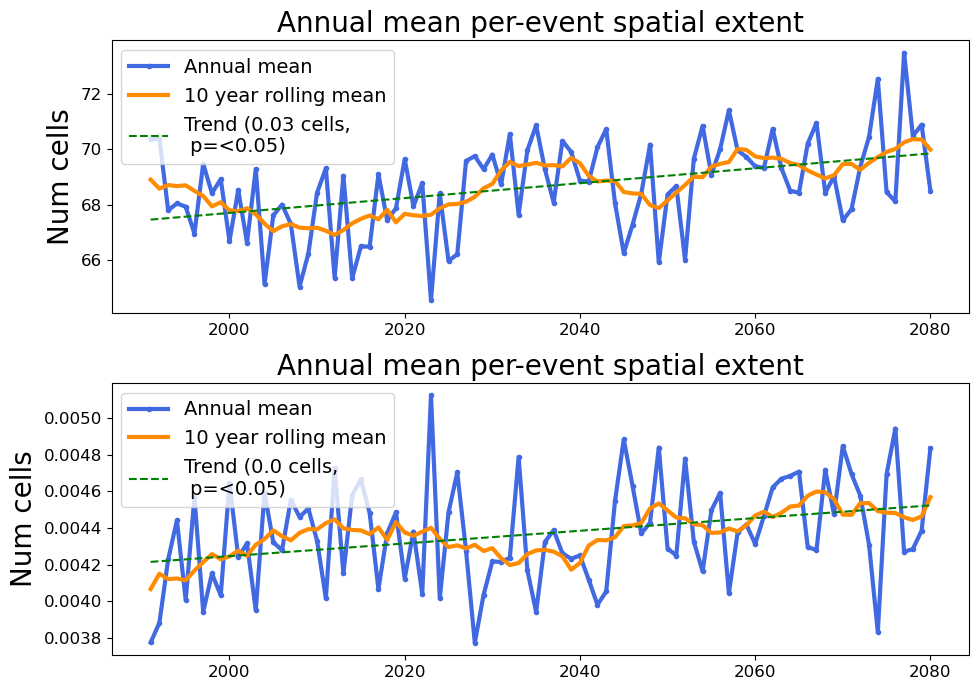

In [8]:
fig, axs = plt.subplots(nrows = 2, figsize=(10, 7), sharex=False)

make_subplot(axs[0], annual_mean_sm, "Num cells", "Annual mean per-event spatial extent", 2, "cells")
make_subplot(axs[1], annual_mean_fu, "Num cells", "Annual mean per-event spatial extent", 2, "cells")

plt.tight_layout()

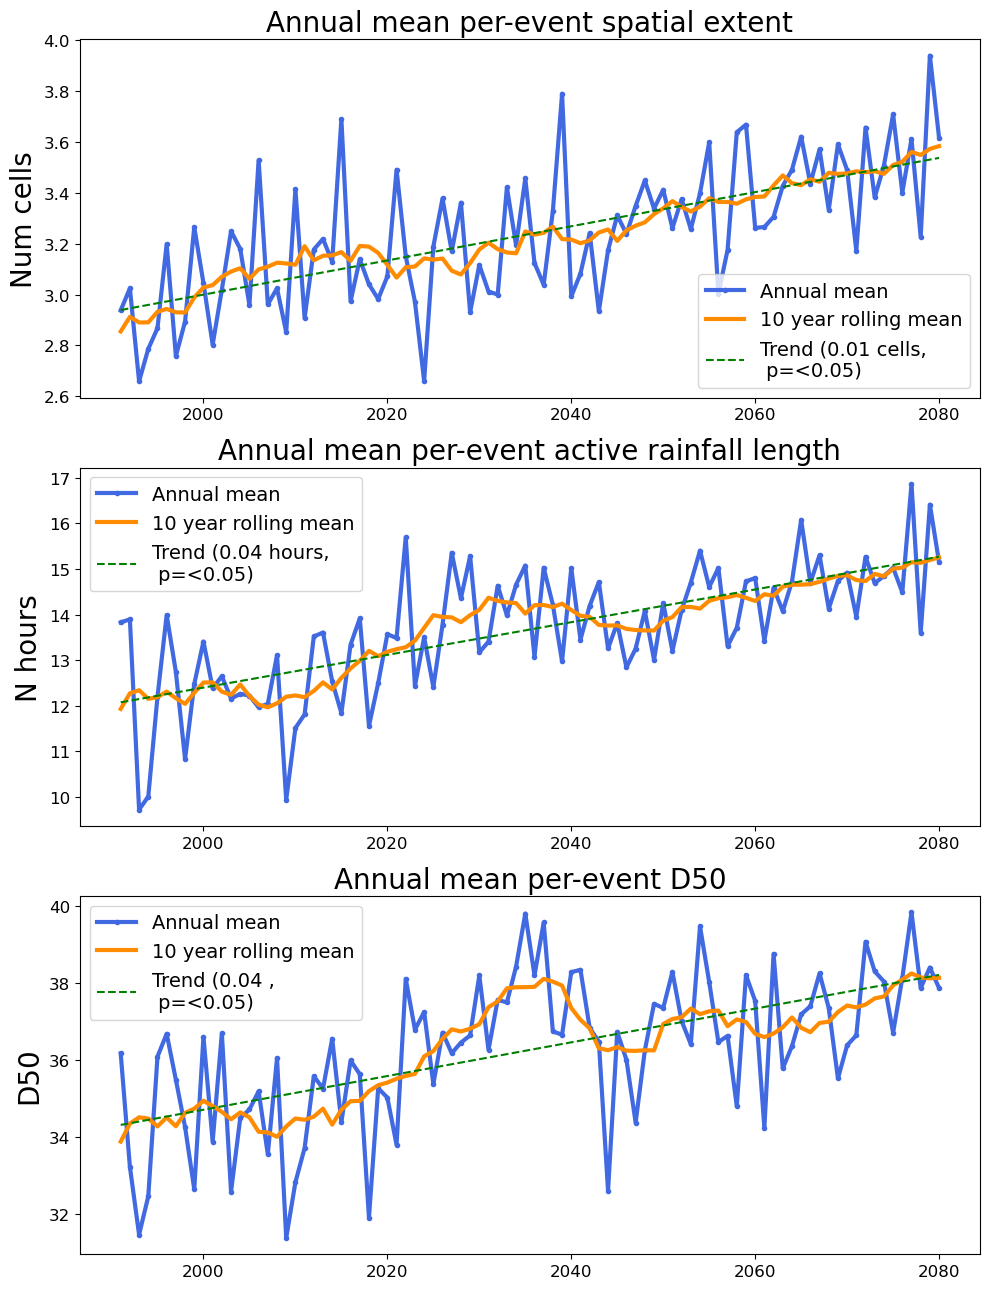

In [13]:
fig, axs = plt.subplots(nrows = 3, figsize=(10, 13), sharex=False)

make_subplot(axs[0], annual_mean_cluster_n_cells_t50, "Num cells", "Annual mean per-event spatial extent", 2, "cells")
make_subplot(axs[1], annual_mean_length_active_rain, "N hours", "Annual mean per-event active rainfall length",2, "hours")

make_subplot(axs[2], annual_mean_d50, "D50", "Annual mean per-event D50",2, "")

plt.tight_layout()

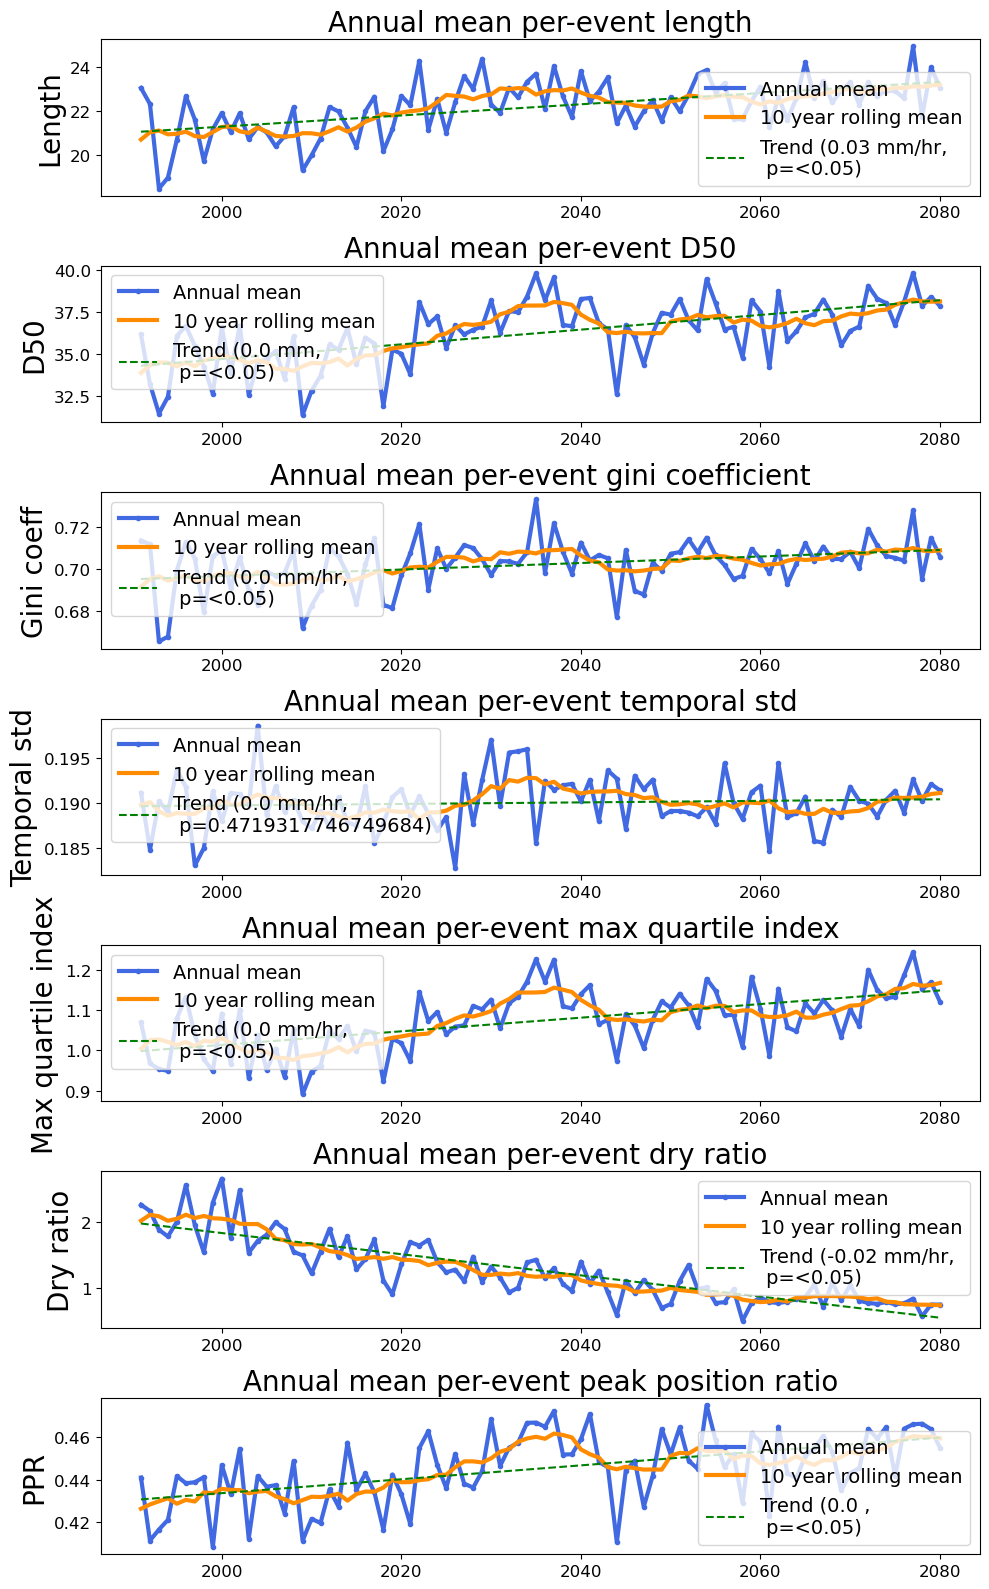

In [10]:
fig, axs = plt.subplots(nrows = 7, figsize=(10, 16), sharex=False)

make_subplot(axs[0], annual_mean_length, "Length", "Annual mean per-event length", 
             2, "mm/hr")
make_subplot(axs[1], annual_mean_d50, "D50", "Annual mean per-event D50",1, "mm")
make_subplot(axs[2], annual_mean_gini, "Gini coeff", "Annual mean per-event gini coefficient", 
             2, "mm/hr")
make_subplot(axs[3], annual_mean_tstd, "Temporal std", "Annual mean per-event temporal std", 
             2, "mm/hr")
make_subplot(axs[4], annual_mean_mqi, "Max quartile index", "Annual mean per-event max quartile index", 
             2, "mm/hr")
make_subplot(axs[5], annual_mean_dr, "Dry ratio", "Annual mean per-event dry ratio", 
             2, "mm/hr")
make_subplot(axs[6], annual_mean_ppr, "PPR", "Annual mean per-event peak position ratio",1, "")

plt.tight_layout()

In [ ]:
df = rainfall_events_all_df
annual_mean_length = (df.groupby("start_year", observed=True)["length"].mean())
annual_mean_length_active_rain = (df.groupby("start_year", observed=True)["length_of_active_rain"].mean())
annual_mean_d50 = (df.groupby("start_year", observed=True)["d50_n"].mean())
annual_mean_gini = (df.groupby("start_year", observed=True)["gini_n"].mean())
annual_mean_ppr = (df.groupby("start_year", observed=True)["peak_position_ratio_n"].mean())
annual_mean_tstd = (df.groupby("start_year", observed=True)["time_based_std_n"].mean())
annual_mean_mqi = (df.groupby("start_year", observed=True)["max_quartile_index_n"].mean())
annual_mean_dr = (df.groupby("start_year", observed=True)["dry_ratio_n"].mean())

In [ ]:
fig, axs = plt.subplots(nrows = 2, figsize=(10, 5), sharex=False)

make_subplot(axs[0], annual_mean_length, "Length", "Annual mean per-event length", 
             2, "mm/hr")
make_subplot(axs[1], annual_mean_length_active_rain, "Length", "Annual mean per-event length of active rain",1, "mm")

plt.tight_layout()

In [15]:
early_events = rainfall_events_all_df[rainfall_events_all_df['start_year']>2020].copy()
med_events = rainfall_events_all_df[(rainfall_events_all_df['start_year']>2020) & (rainfall_events_all_df['start_year'] < 2050)].copy()
late_events = rainfall_events_all_df[(rainfall_events_all_df['start_year']>2050)].copy()

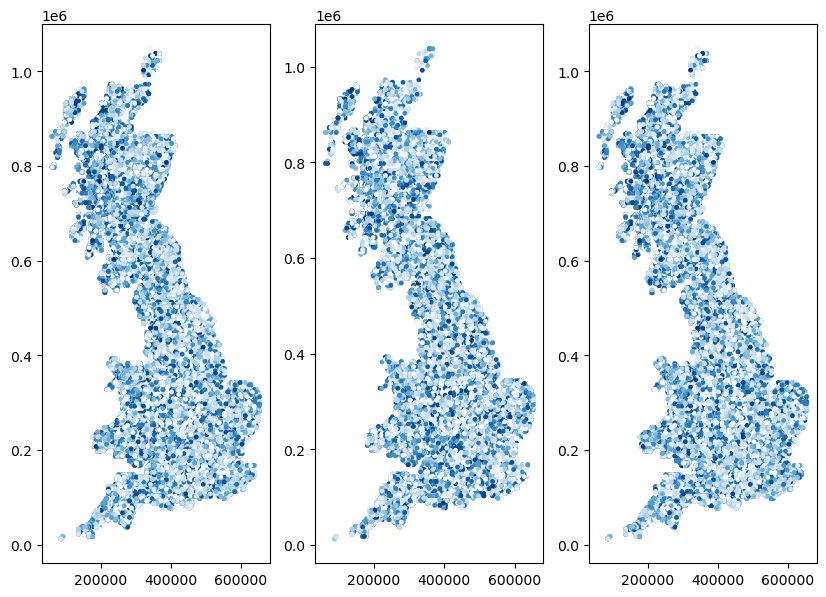

In [17]:
fig, axs = plt.subplots(figsize=(10, 7), ncols=3)
for ax_num, df in enumerate([early_events, med_events, late_events]):
    sc = axs[ax_num].scatter(df['x_coord'], df['y_coord'], c=df['d50_n'], cmap='Blues', s=6, alpha=1)
#     plt.colorbar(sc, label='Length')
#     ax.set_aspect('equal')
#     plt.show()

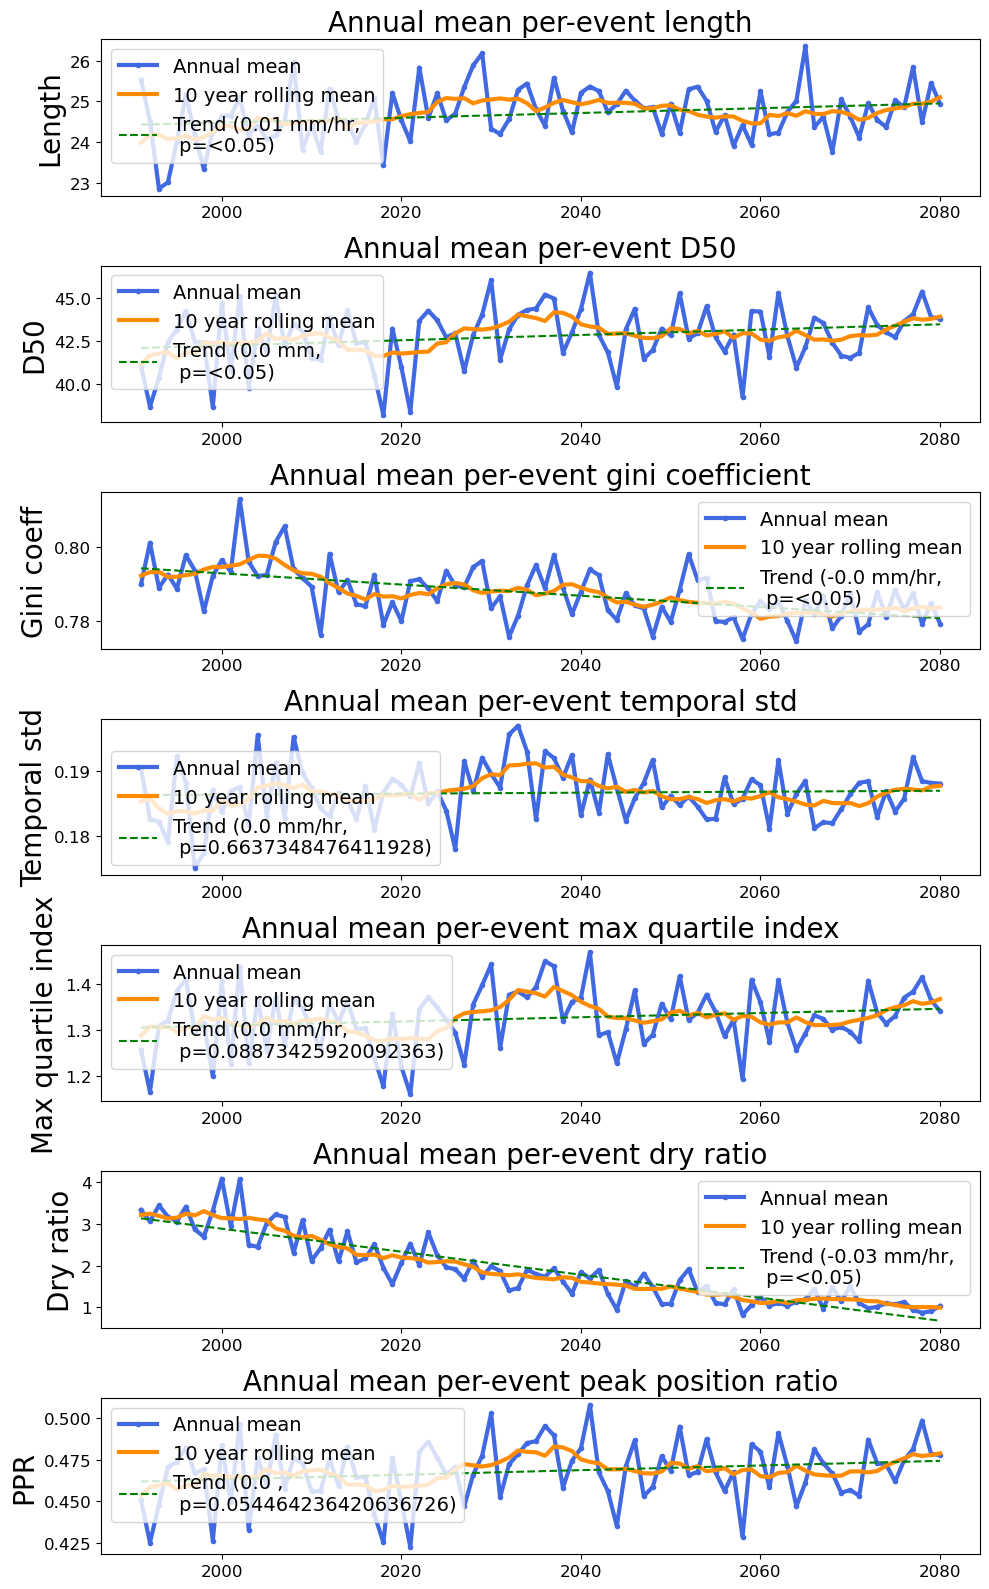

In [9]:
fig, axs = plt.subplots(nrows = 7, figsize=(10, 16), sharex=False)

make_subplot(axs[0], annual_mean_length, "Length", "Annual mean per-event length", 
             2, "mm/hr")
make_subplot(axs[1], annual_mean_d50, "D50", "Annual mean per-event D50",1, "mm")
make_subplot(axs[2], annual_mean_gini, "Gini coeff", "Annual mean per-event gini coefficient", 
             2, "mm/hr")
make_subplot(axs[3], annual_mean_tstd, "Temporal std", "Annual mean per-event temporal std", 
             2, "mm/hr")
make_subplot(axs[4], annual_mean_mqi, "Max quartile index", "Annual mean per-event max quartile index", 
             2, "mm/hr")
make_subplot(axs[5], annual_mean_dr, "Dry ratio", "Annual mean per-event dry ratio", 
             2, "mm/hr")
make_subplot(axs[6], annual_mean_ppr, "PPR", "Annual mean per-event peak position ratio",1, "")

plt.tight_layout()